# Evaporator coil line: DES and Monte Carlo analysis

> **All data is fictional.** It does not describe any real company or plant.

This notebook walks through the analysis using the committed result files in `results/`
(produced by `make all`). It also runs one live replication to show the model's per-unit
instrumentation. Each table below is read from a CSV file, so the notebook always matches
the results on disk.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from evapsim import plots
from evapsim.config import load_config
from evapsim.model import simulate_replication

plots.apply_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
RES = ROOT / "results"
FIG = RES / "figures"
cfg = load_config()
print(f"Takt time: {cfg.takt_s:.1f} s | demand {cfg.demand_per_day:.0f} units/day | "
      f"mix multiplier {cfg.mix_ct_multiplier:.3f}")

Takt time: 75.8 s | demand 380 units/day | mix multiplier 1.005


## 1. Static capacity check (hand calculation)

Effective time per unit = CT × mix multiplier × (1 + MTTR/MTBF) + P(model switch) × C/O / batch size
(+ rework load at S4), divided by the number of servers. This ignores blocking and starving, so it
gives an upper bound on throughput.

In [2]:
cap = pd.read_csv(RES / "static_capacity.csv")
cap[["station_id", "station", "servers", "t_eff_s", "capacity_per_day", "load_vs_takt"]].round(2)

,station_id,station,servers,t_eff_s,capacity_per_day,load_vs_takt
0,1,Tube Cut & Bend,1,45.38,634.70,0.60
1,2,Fin-Pack Assembly,1,76.64,375.79,1.01
2,3,Tube Expansion,1,50.92,565.59,0.67
3,4,Header Brazing,1,112.62,255.72,1.49
4,5,Pressure & Leak Test,1,64.61,445.77,0.85
5,6,Casing & Final Assembly,2,60.30,477.61,0.80
6,7,Inspection & Packing,1,45.22,636.82,0.60


## 2. Input analysis: distribution fitting of the time-study samples

In [3]:
ia = pd.read_csv(RES / "input_analysis.csv")
ia.pivot_table(index="station_id", columns="distribution", values="aic").round(1).join(
    ia[ia.selected].set_index("station_id")[["sample_mean_s", "spec_mean_s", "spec_mean_in_ci",
                                            "ks_pvalue", "distribution"]]
    .rename(columns={"distribution": "selected"}))

,gamma,lognormal,weibull,sample_mean_s,spec_mean_s,spec_mean_in_ci,ks_pvalue,selected
station_id,,,,,,,,
1,250.9,251.0,253.7,41.01,42.0,True,0.9544,lognormal
2,309.8,310.3,313.3,58.40,55.0,True,0.9671,lognormal
3,261.2,259.6,276.2,48.15,48.0,True,0.8088,lognormal
4,324.2,324.9,324.2,78.20,78.0,True,0.9744,lognormal
5,259.2,258.5,267.3,60.49,60.0,True,0.1687,lognormal
6,358.7,359.1,360.4,125.38,120.0,True,0.6676,lognormal
7,226.7,226.0,238.7,44.86,45.0,True,0.6942,lognormal


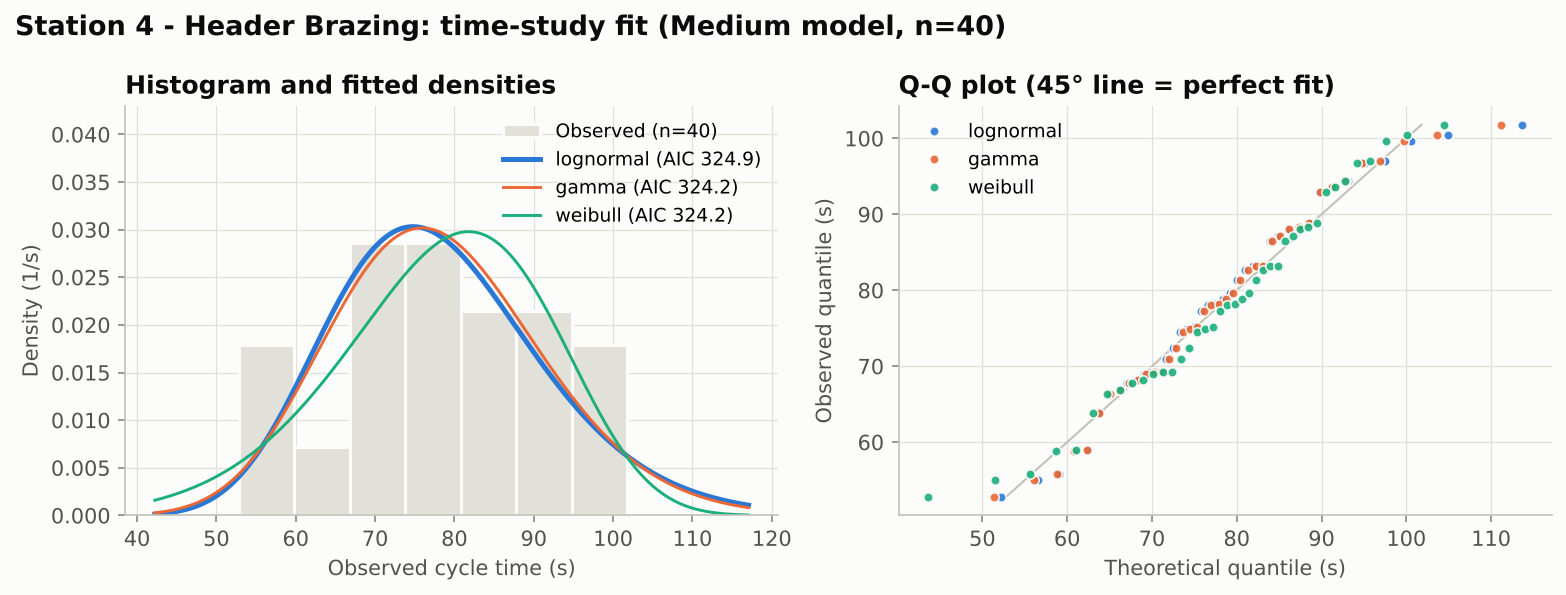

In [4]:
display(Image(filename=str(FIG / "input_fit_S4.png"), width=900))

## 3. One replication up close

We run replication 0 with per-unit logging and draw a Gantt chart of the first units through the
line. A gap between a unit's end at one station and its start at the next is time spent queuing.
A machine that holds a finished unit is *blocked*.

In [5]:
res = simulate_replication(cfg, rep=0, keep_units=True)
units = pd.DataFrame(res.units)
first = units[units.status == "good"].nsmallest(14, "uid")
fig, ax = plt.subplots(figsize=(11, 4.2))
for i in range(1, 8):
    ax.barh(first.uid, (first[f"end_S{i}"] - first[f"start_S{i}"]) / 60,
            left=first[f"start_S{i}"] / 60, color=plots.SERIES[(i - 1) % 8], height=0.7,
            label=f"S{i}")
ax.invert_yaxis()
ax.set_xlabel("Simulated time (productive minutes)")
ax.set_ylabel("Unit id")
ax.set_title("First good units through the line (bar = processing at a station)", loc="left")
ax.legend(ncol=7, loc="lower center", bbox_to_anchor=(0.5, 1.06))
plt.show()
print(f"Replication 0: {res.daily_output.mean():.1f} good units/day, mean lead time "
      f"{res.lead_times_min.mean():.1f} min, WIP {res.wip_avg:.1f}")
print(f"Conservation: released {res.total_released} = departed {res.total_departed} "
      f"+ in line {res.wip_end}")

Replication 0: 222.8 good units/day, mean lead time 39.7 min, WIP 19.1
Conservation: released 4991 = departed 4976 + in line 15


## 4. Baseline Monte Carlo results (S0)

In [6]:
kpi = pd.read_csv(RES / "baseline_kpis.csv")
kpi[["label", "unit", "mean", "ci_low", "ci_high", "n"]].round(3)

,label,unit,mean,ci_low,ci_high,n
0,Throughput,units/day,231.097,230.465,231.729,500
1,Takt compliance (days >= demand),share of days,0.000,0.000,0.000,500
2,Demand attainment,TH / demand,0.608,0.606,0.610,500
3,"Lead time, mean",min,37.869,37.757,37.980,500
4,"Lead time, P50",min,33.819,33.743,33.896,500
5,"Lead time, P90",min,52.527,52.115,52.939,500
6,"Lead time, P95",min,71.377,70.682,72.072,500
7,"Batch lead time, mean",min,71.377,71.174,71.580,500
8,"WIP, time average",units,18.960,18.938,18.983,500
9,WIP from Little's law (TH x LT),units,18.959,18.936,18.983,500


In [7]:
pd.read_csv(RES / "baseline_stations.csv")[
    ["station_id", "station", "busy", "changeover", "down", "blocked", "starved", "active",
     "busy_plus_blocked", "uptime", "fpy", "buffer_in_front_avg"]].round(3)

,station_id,station,busy,changeover,down,blocked,starved,active,busy_plus_blocked,uptime,fpy,buffer_in_front_avg
0,1,Tube Cut & Bend,0.358,0.000,0.026,0.616,0.000,0.384,0.974,0.932,0.995,NaN
1,2,Fin-Pack Assembly,0.466,0.158,0.023,0.337,0.015,0.648,0.803,0.953,0.995,4.862
2,3,Tube Expansion,0.405,0.000,0.022,0.483,0.090,0.427,0.888,0.949,0.990,3.597
3,4,Header Brazing,0.659,0.190,0.092,0.026,0.033,0.940,0.685,0.878,0.985,4.529
4,5,Pressure & Leak Test,0.499,0.000,0.036,0.000,0.465,0.535,0.499,0.932,0.975,0.209
5,6,Casing & Final Assembly,0.486,0.000,0.000,0.000,0.514,0.486,0.486,1.000,0.997,0.015
6,7,Inspection & Packing,0.364,0.000,0.000,0.000,0.636,0.364,0.364,1.000,0.998,0.017


The **active share** (busy + down + changeover) is highest at S4, so Header Brazing is the
bottleneck in every replication. The brief's literal "busy + blocked" rule would choose S1
instead, because S1 spends about 60 % of its time blocked *by* the bottleneck. This is why the
active-period method is used (see ASSUMPTIONS A21).

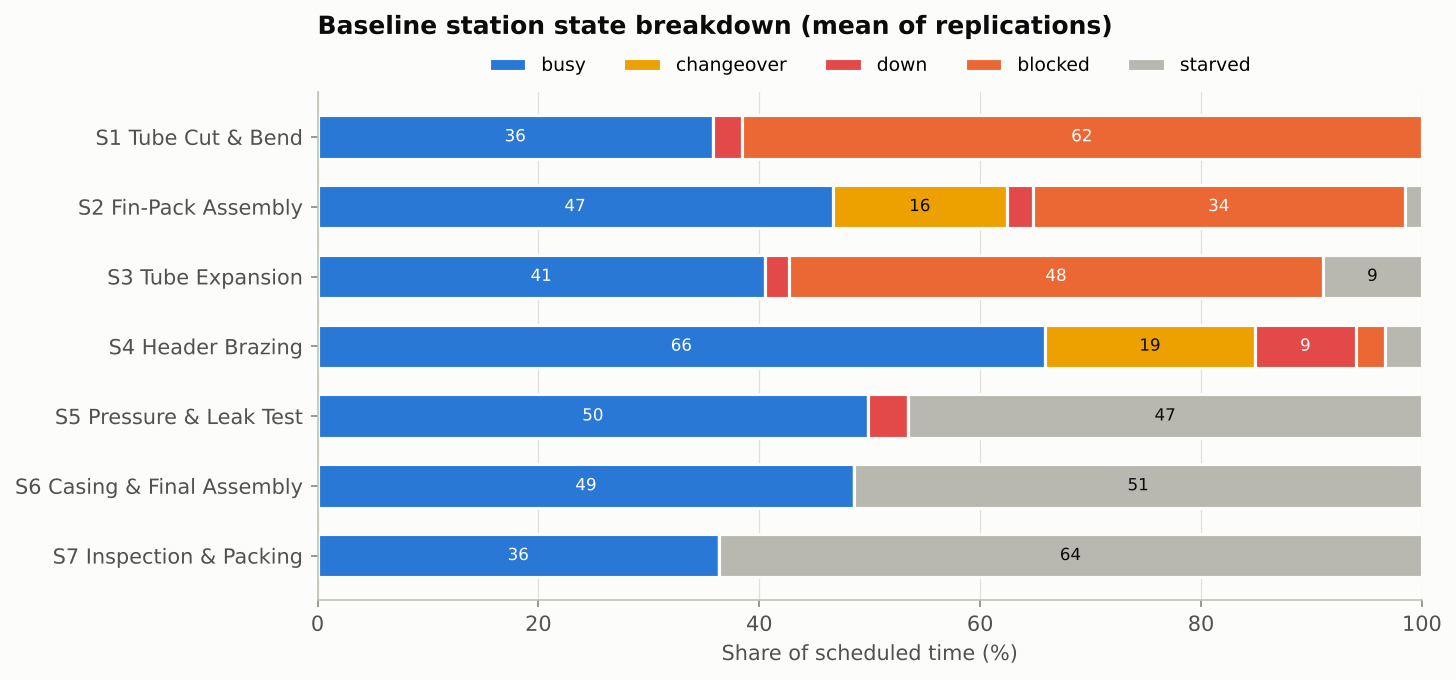

In [8]:
display(Image(filename=str(FIG / "baseline_station_states.png"), width=900))

In [9]:
pd.read_csv(RES / "convergence_required_replications.csv")

,metric,target_rel_half_width_pct,required_replications,replications_run,achieved_rel_half_width_pct
0,throughput_per_day,0.5,152,500,0.2735
1,throughput_per_day,1.0,40,500,0.2735
2,throughput_per_day,2.0,12,500,0.2735
3,lt_mean_min,0.5,175,500,0.2938
4,lt_mean_min,1.0,46,500,0.2938
5,lt_mean_min,2.0,14,500,0.2938


## 5. Validation against the observed (fictional) line data

In [10]:
pd.read_csv(RES / "validation_summary.csv").drop(columns=["n_sim_periods"]).round(3)

,measure,unit,observed_mean,n_observed,simulated_mean,sim_pi95_low,sim_pi95_high,error_pct,within_target,prediction_interval_p,welch_t_p,verdict
0,Mean daily output,units/day,230.400,20.0,231.097,215.192,245.002,0.302,True,0.870,0.862,valid
1,Mean batch lead time,min,72.031,242.0,71.377,67.542,76.751,-0.908,True,0.691,0.622,valid
2,Station utilisation (mean abs. error),percentage points,0.468,NaN,0.462,NaN,NaN,0.895,True,NaN,NaN,valid


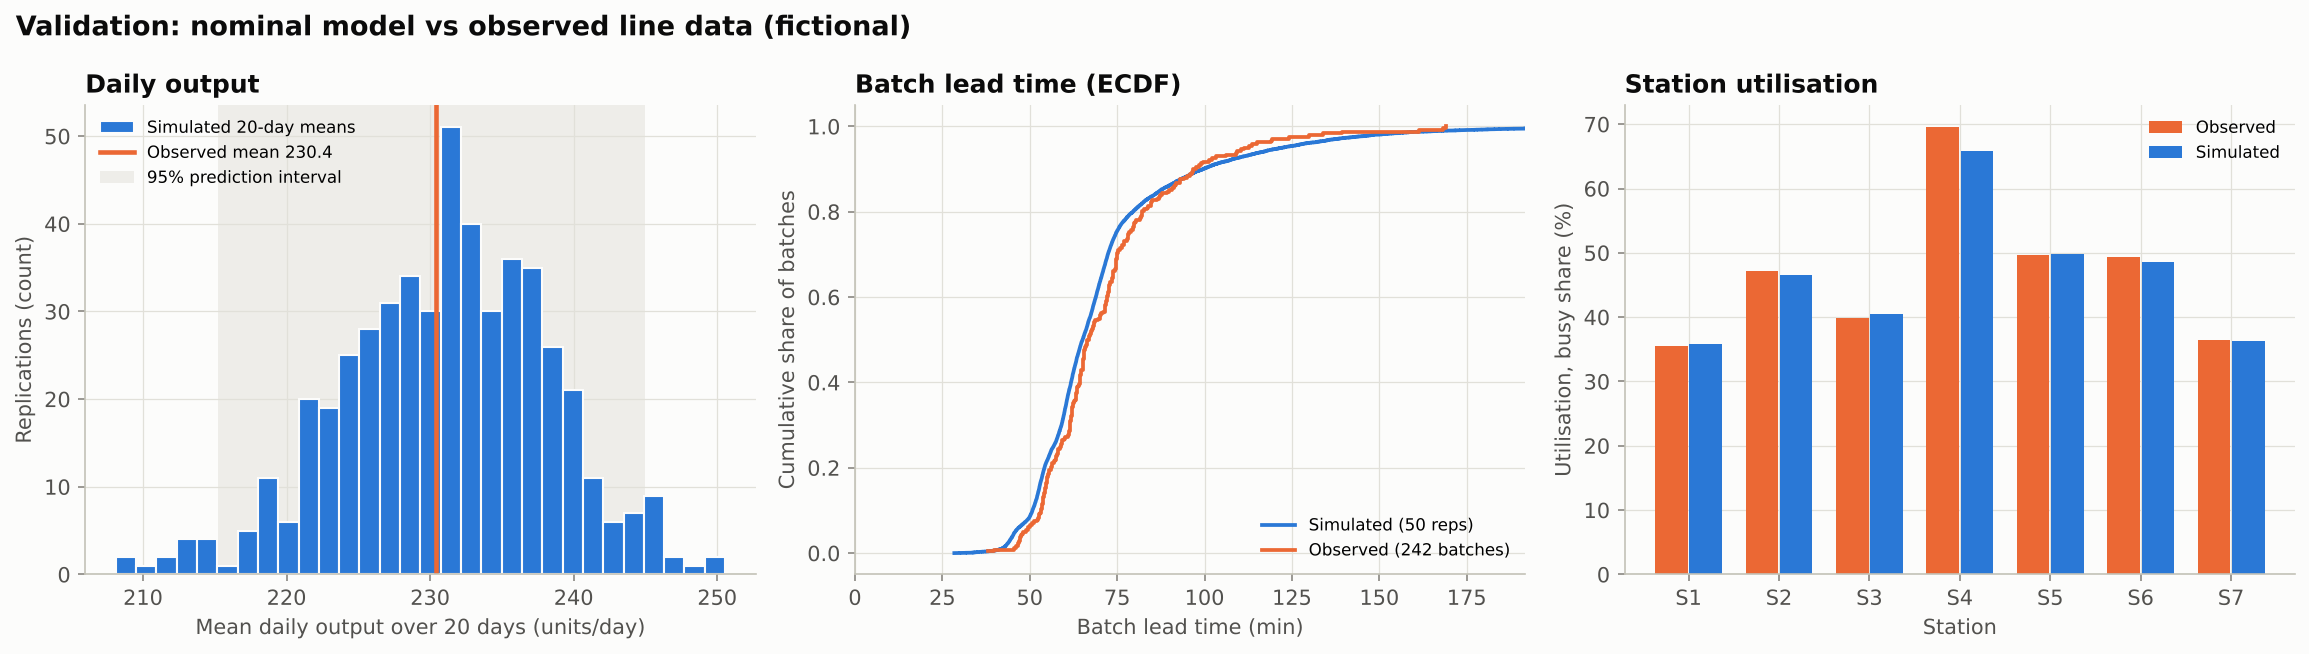

In [11]:
display(Image(filename=str(FIG / "validation.png"), width=1000))

## 6. Scenarios: paired differences against S0 with common random numbers

In [12]:
summ = pd.read_csv(RES / "scenario_summary.csv")
summ[["scenario", "name", "throughput_per_day_mean", "throughput_per_day_ci_low",
      "throughput_per_day_ci_high", "takt_compliance_mean", "lt_mean_min_mean", "wip_avg_mean",
      "bottleneck_station", "bottleneck_share"]].round(2)

,scenario,name,throughput_per_day_mean,throughput_per_day_ci_low,throughput_per_day_ci_high,takt_compliance_mean,lt_mean_min_mean,wip_avg_mean,bottleneck_station,bottleneck_share
0,S0,Baseline,231.10,230.46,231.73,0.00,37.87,18.96,4,1.0
1,S1,Larger buffers,237.02,236.40,237.64,0.00,65.80,33.83,4,1.0
2,S2,SMED,250.47,249.80,251.13,0.00,36.26,19.67,4,1.0
3,S3,Second brazing fixture,302.57,301.88,303.26,0.01,29.81,19.48,2,1.0
4,S4,Preventive maintenance,243.42,242.86,243.98,0.00,36.28,19.13,4,1.0
5,S5,Combined (SMED + PM + buffers 8),268.22,267.65,268.79,0.00,49.19,28.61,4,1.0
6,S6,Combined + second fixture (extension),374.69,374.04,375.35,0.49,30.03,24.30,2,1.0


In [13]:
pdiff = pd.read_csv(RES / "scenario_paired_differences.csv")
pdiff[pdiff.metric.isin(["throughput_per_day", "lt_mean_min"])][
    ["scenario", "metric", "diff_mean", "diff_ci_low", "diff_ci_high", "rel_change_pct",
     "p_value", "crn_corr"]].round(3)

,scenario,metric,diff_mean,diff_ci_low,diff_ci_high,rel_change_pct,p_value,crn_corr
0,S1,throughput_per_day,5.922,5.768,6.077,2.563,0.0,0.970
2,S1,lt_mean_min,27.933,27.838,28.028,73.763,0.0,0.954
7,S2,throughput_per_day,19.372,19.162,19.583,8.383,0.0,0.949
9,S2,lt_mean_min,-1.609,-1.640,-1.578,-4.248,0.0,0.961
14,S3,throughput_per_day,71.476,70.937,72.015,30.929,0.0,0.669
16,S3,lt_mean_min,-8.058,-8.138,-7.977,-21.278,0.0,0.693
21,S4,throughput_per_day,12.322,12.071,12.574,5.332,0.0,0.918
23,S4,lt_mean_min,-1.592,-1.641,-1.542,-4.203,0.0,0.912
28,S5,throughput_per_day,37.123,36.892,37.353,16.064,0.0,0.932
30,S5,lt_mean_min,11.319,11.279,11.358,29.890,0.0,0.941


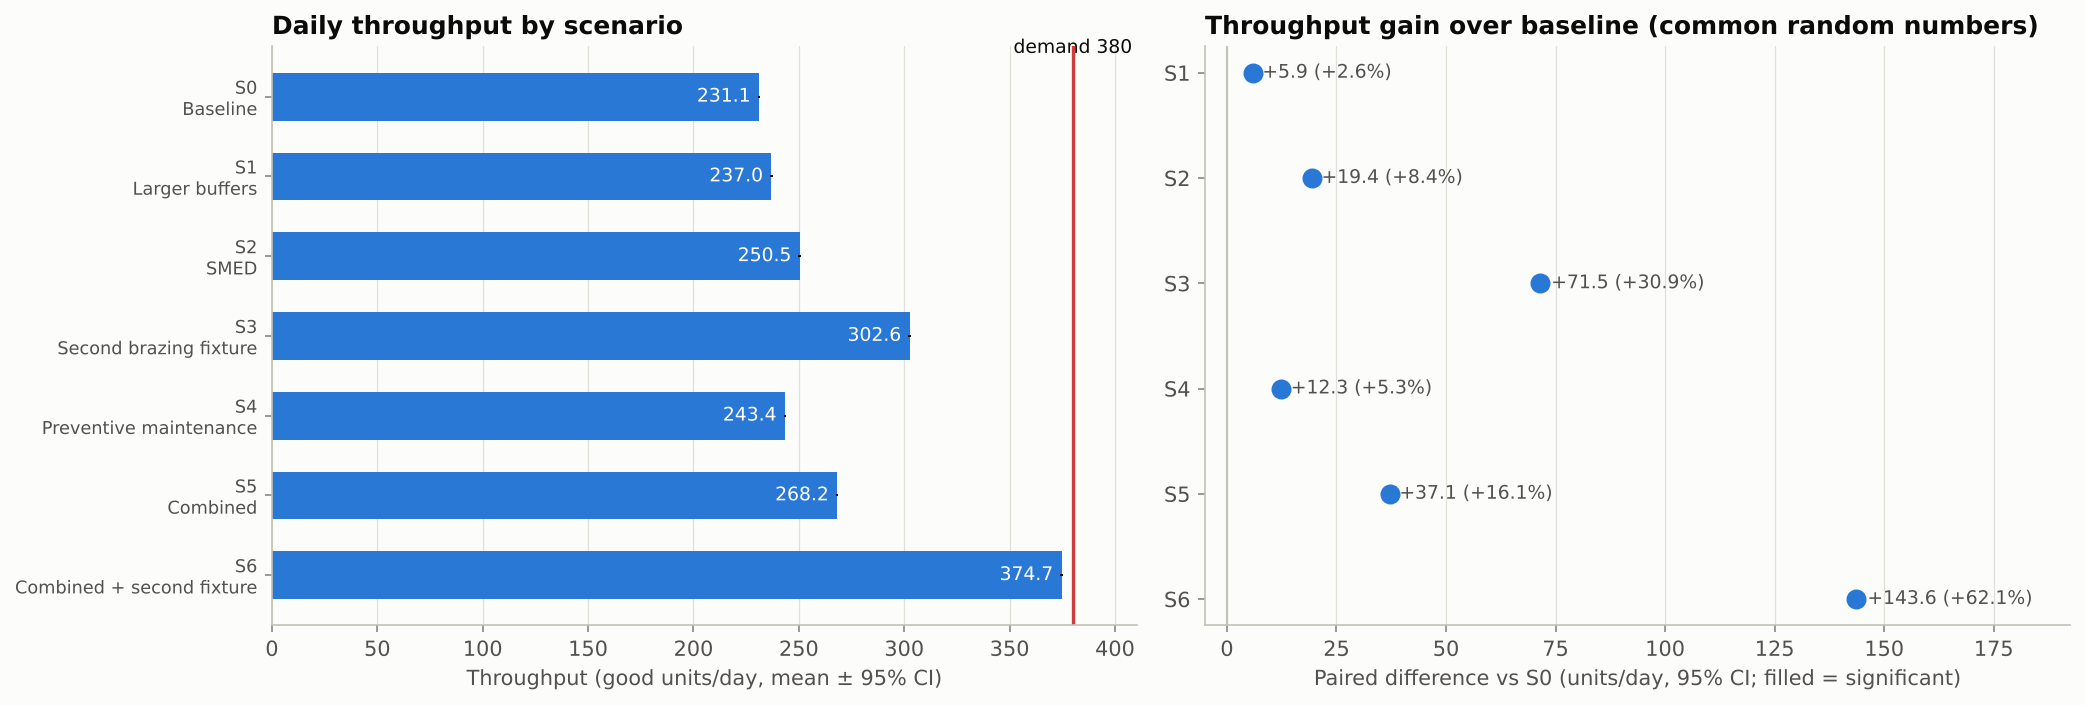

In [14]:
display(Image(filename=str(FIG / "scenario_comparison.png"), width=1000))

## 7. One-at-a-time sensitivity

In [15]:
sens = pd.read_csv(RES / "sensitivity_oat.csv")
sens[["label", "level", "value", "th_diff", "th_diff_ci_low", "th_diff_ci_high",
      "elasticity"]].head(12).round(2)

,label,level,value,th_diff,th_diff_ci_low,th_diff_ci_high,elasticity
0,S4 cycle time,low,70.2,16.64,16.27,17.01,-0.72
1,S4 cycle time,high,85.8,-14.88,-15.25,-14.50,-0.64
2,S4 MTBF,low,162.0,-2.53,-2.92,-2.14,0.11
3,S4 MTBF,high,198.0,2.06,1.71,2.40,0.09
4,All buffer sizes (±1 unit),low,4.0,-2.83,-3.00,-2.66,0.06
5,All buffer sizes (±1 unit),high,6.0,1.62,1.49,1.75,0.03
6,S4 MTTR,low,22.5,2.14,1.97,2.30,-0.09
7,S4 MTTR,high,27.5,-2.06,-2.21,-1.91,-0.09
8,S5 MTTR,low,27.0,0.79,0.70,0.89,-0.03
9,S5 MTTR,high,33.0,-0.80,-0.89,-0.70,-0.03


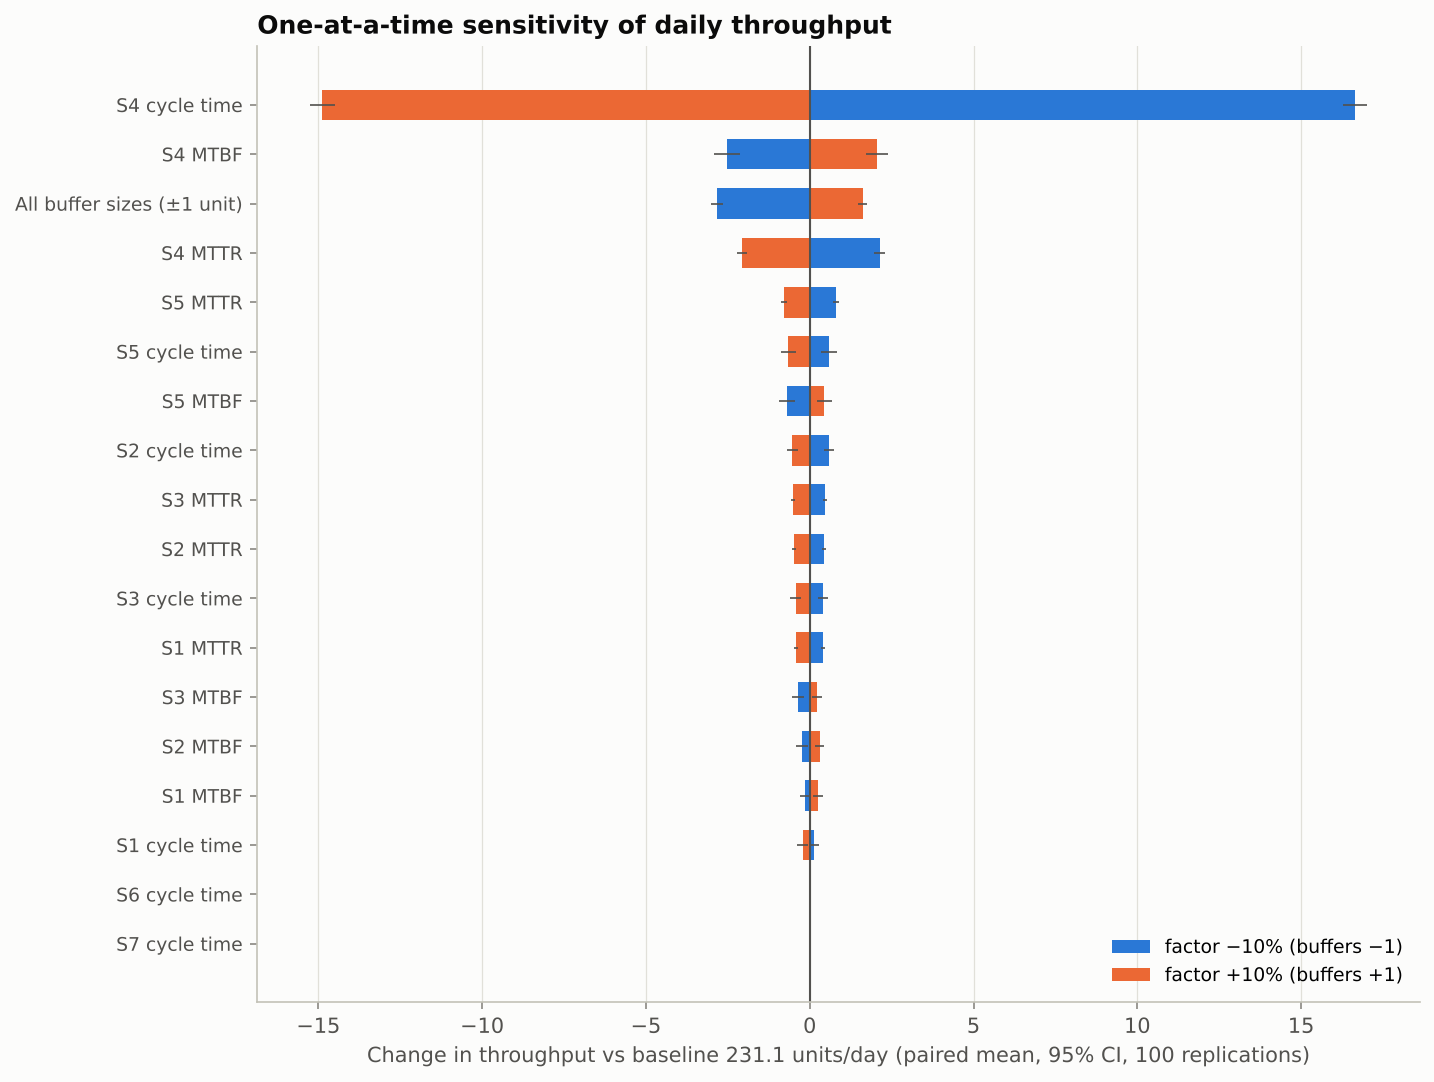

In [16]:
display(Image(filename=str(FIG / "sensitivity_tornado.png"), width=900))

## 8. Value stream maps

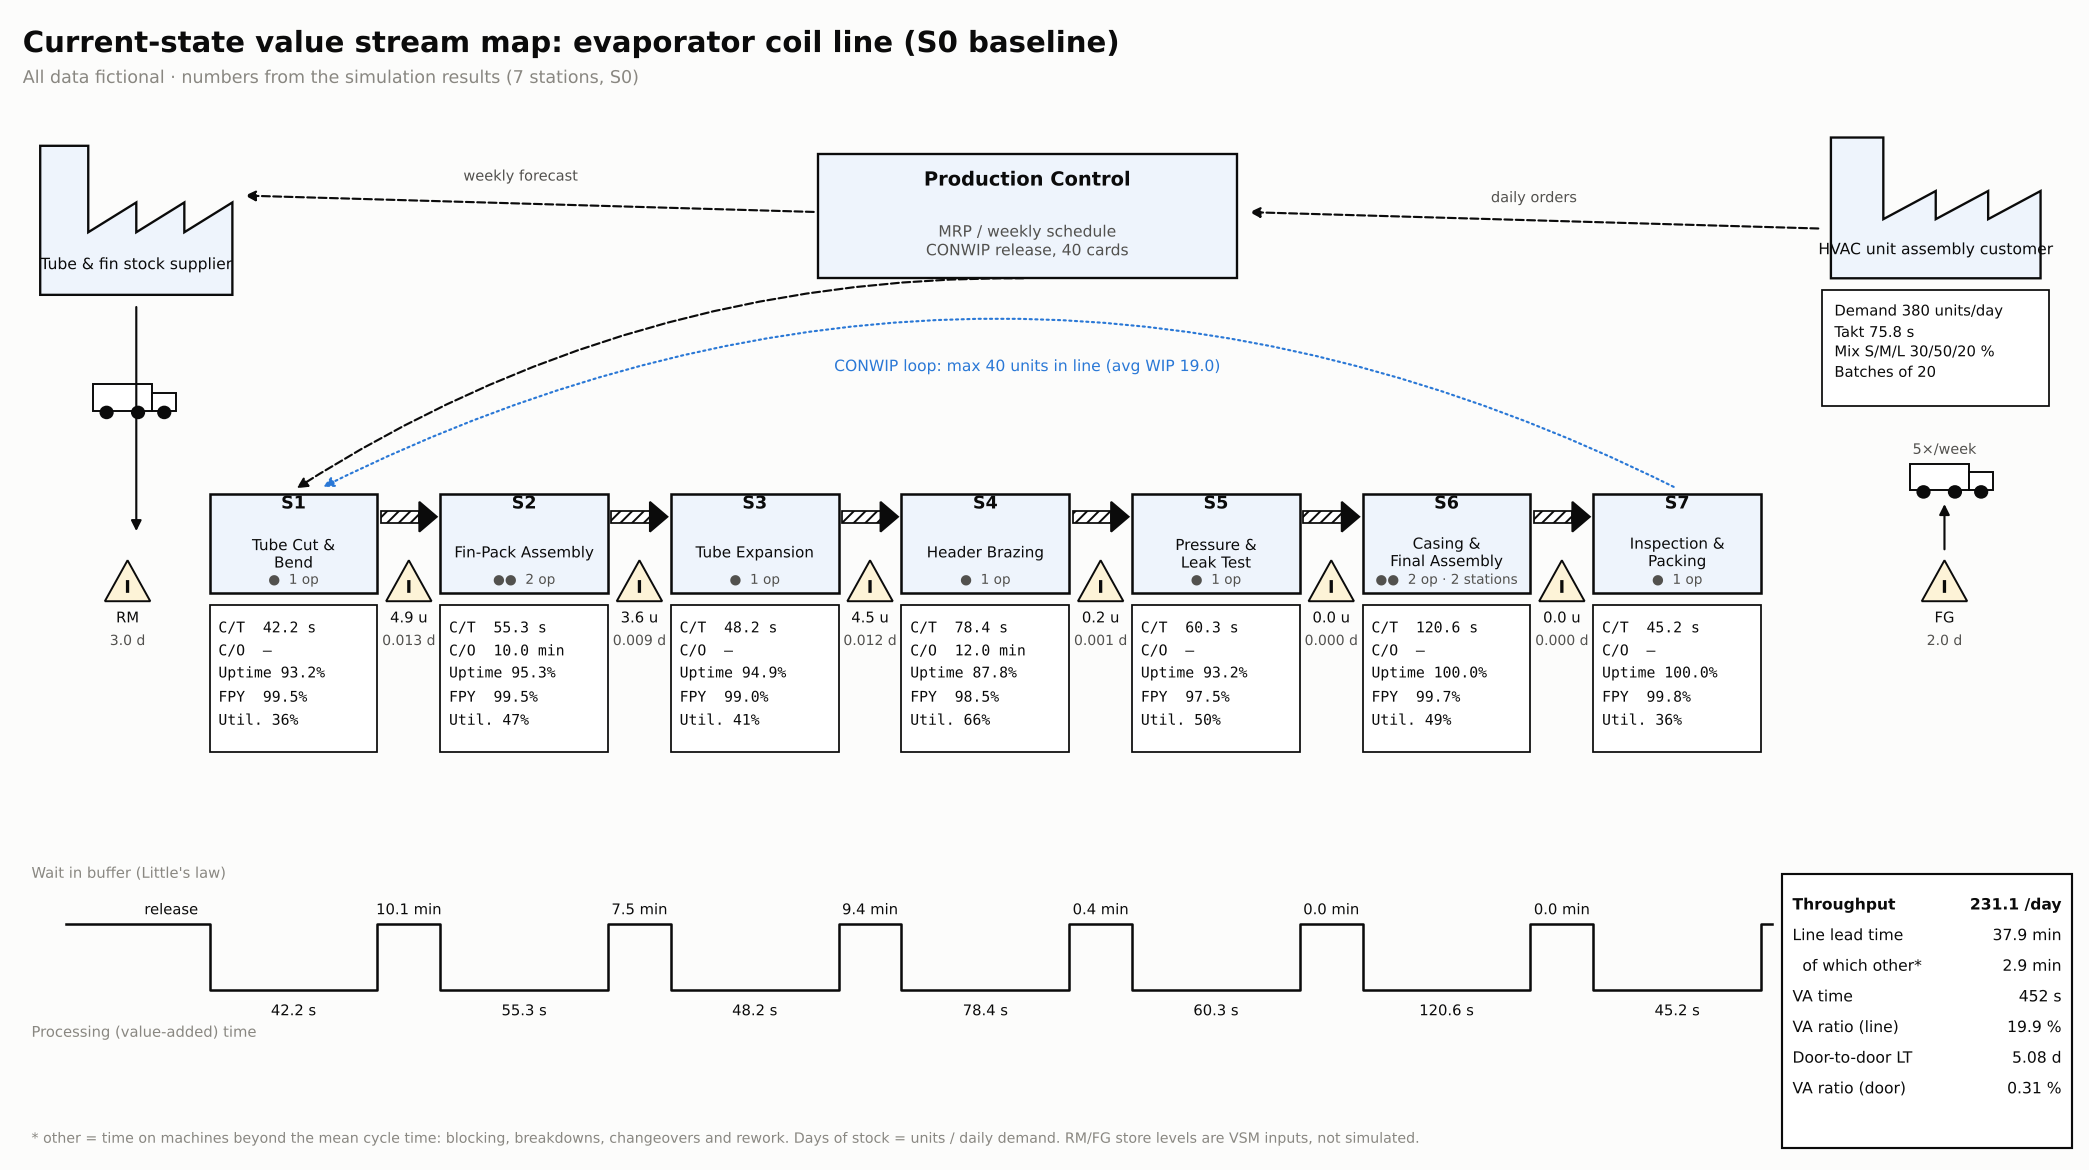

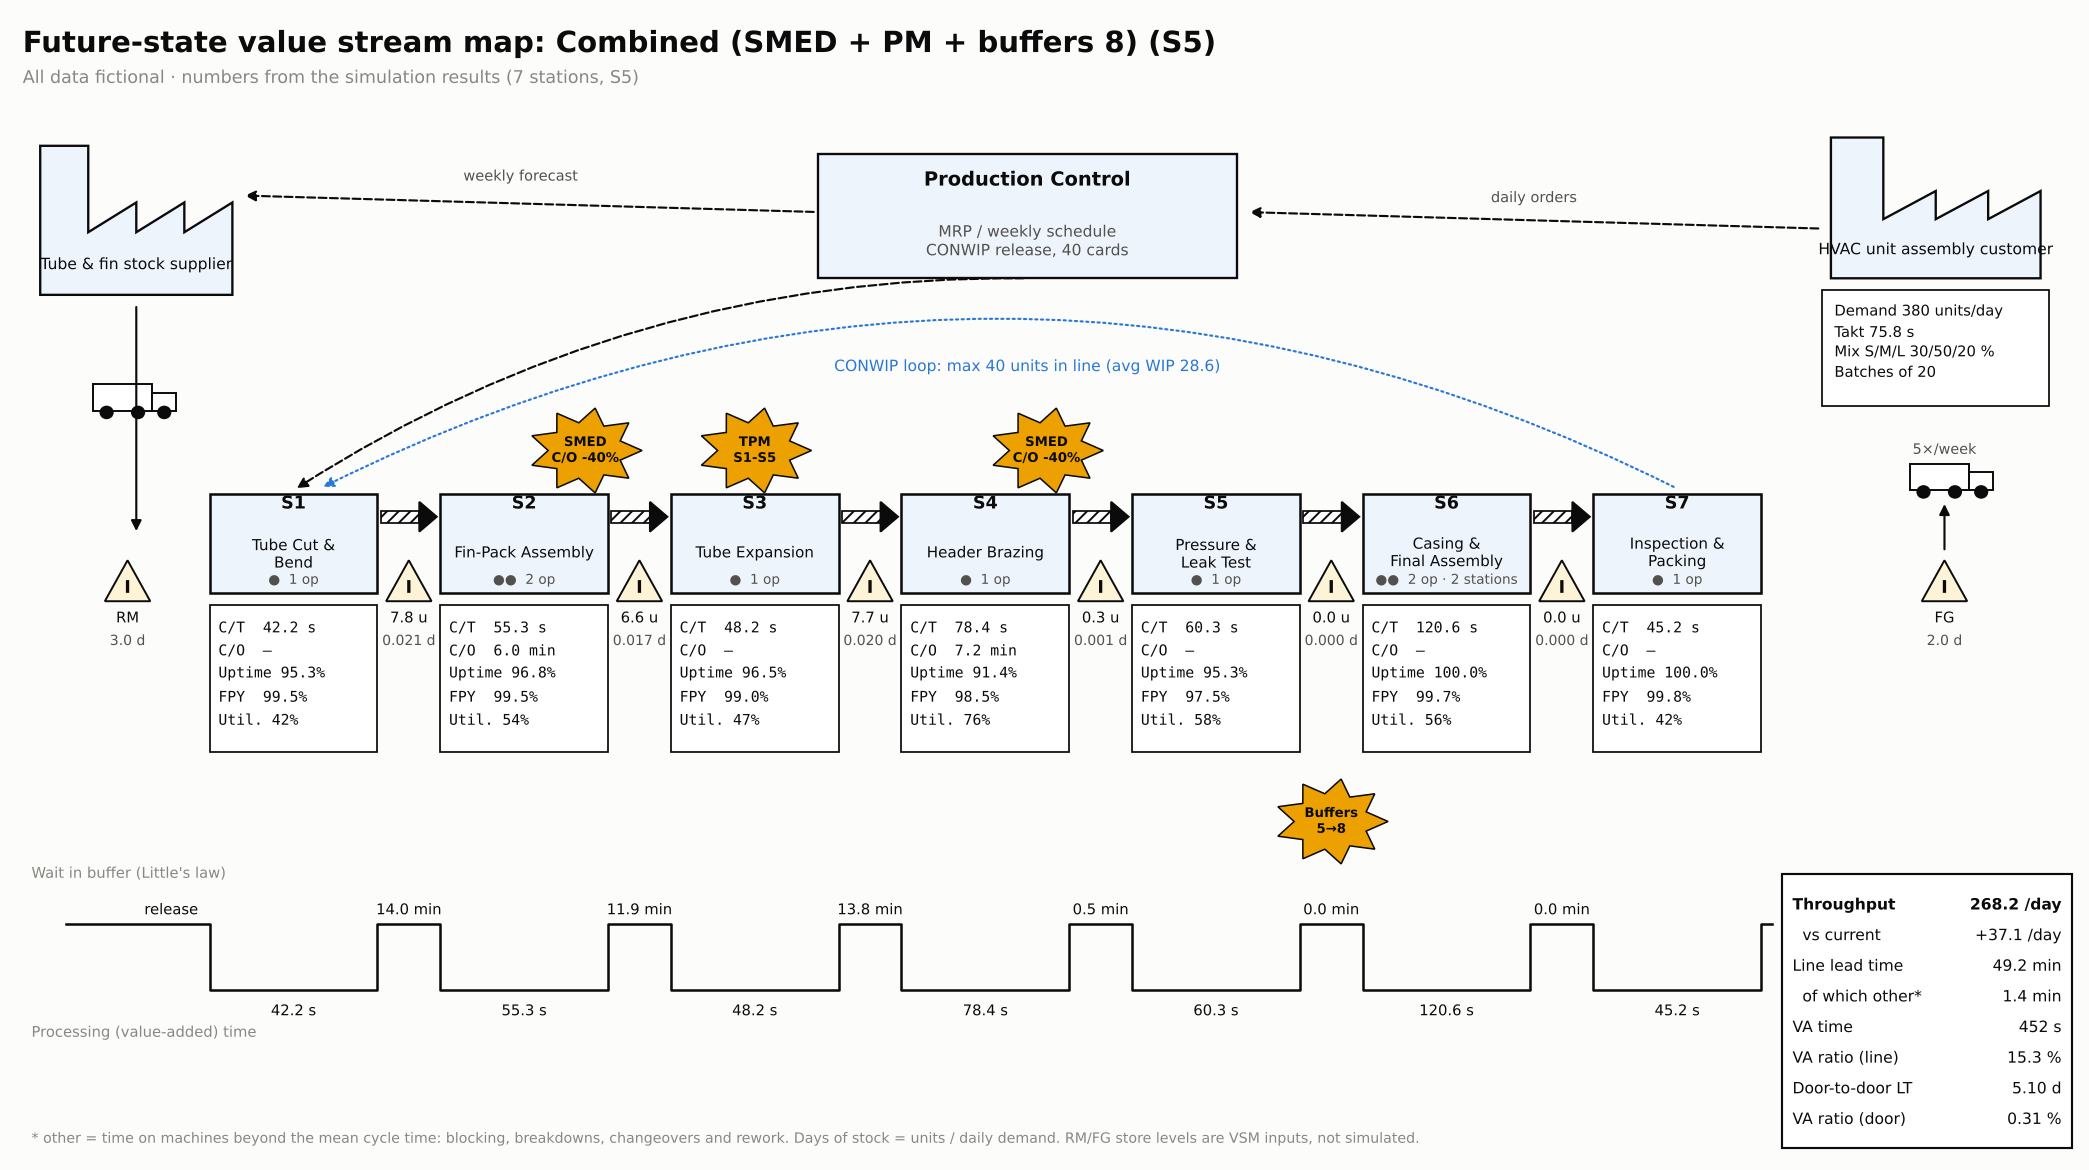

,state,scenario,throughput_per_day,line_lead_time_min,other_delays_min,va_time_s,va_ratio_line_pct,door_to_door_lead_time_days,va_ratio_door_pct,wip
0,current,S0,231.097,37.869,2.889,451.646,19.878,5.079,0.309,18.960
1,future,S5,268.220,49.187,1.425,451.751,15.307,5.102,0.307,28.614


In [17]:
display(Image(filename=str(ROOT / "docs" / "vsm_current.png"), width=1100))
display(Image(filename=str(ROOT / "docs" / "vsm_future.png"), width=1100))
pd.read_csv(RES / "vsm_summary.csv").round(3)

## 9. Conclusions (computed from the result files)

In [18]:
s = summ.set_index("scenario")
th = pdiff[pdiff.metric == "throughput_per_day"].set_index("scenario")
best_single = th.drop(index=[i for i in ("S5", "S6") if i in th.index])["diff_mean"].idxmax()
print(f"Baseline: {s.loc['S0', 'throughput_per_day_mean']:.1f} units/day = "
      f"{s.loc['S0', 'attainment_pct']:.1f} % of demand; bottleneck S"
      f"{int(s.loc['S0', 'bottleneck_station'])} in {100 * s.loc['S0', 'bottleneck_share']:.0f} % "
      "of replications.")
print(f"S5 combined: {th.loc['S5', 'diff_mean']:+.1f} units/day "
      f"[{th.loc['S5', 'diff_ci_low']:.1f}, {th.loc['S5', 'diff_ci_high']:.1f}] "
      f"({th.loc['S5', 'rel_change_pct']:+.1f} %), paired-t p "
      + ("< 0.001" if th.loc['S5', 'p_value'] < 1e-3 else f"= {th.loc['S5', 'p_value']:.3f}"))
print(f"Largest single lever: {best_single} ({s.loc[best_single, 'name']}), "
      f"{th.loc[best_single, 'diff_mean']:+.1f} units/day; the bottleneck then moves to S"
      f"{int(s.loc[best_single, 'bottleneck_station'])}.")
if "S6" in s.index:
    print(f"S6 (S5 + second fixture): {s.loc['S6', 'throughput_per_day_mean']:.1f} units/day, "
          f"takt compliance {100 * s.loc['S6', 'takt_compliance_mean']:.0f} % of days.")

Baseline: 231.1 units/day = 60.8 % of demand; bottleneck S4 in 100 % of replications.
S5 combined: +37.1 units/day [36.9, 37.4] (+16.1 %), paired-t p < 0.001
Largest single lever: S3 (Second brazing fixture), +71.5 units/day; the bottleneck then moves to S2.
S6 (S5 + second fixture): 374.7 units/day, takt compliance 49 % of days.
